# New Dataset – Step 2: Legal vs. Medical Texts

Same analysis as `Administrative_vs_Medical.ipynb` (paper, Section 4.1), now for the new dataset:
are the Easy Language outputs of each model **different for legal and medical texts**?

* **Welch's t-test** (two-sided, unequal variances) per metric
* **Mean difference** (Legal − Medical) with **95% CI** (Welch–Satterthwaite)
* **Cohen's d** (weighted pooled SD)
* **Holm correction** across the 10 metrics of each comparison, α = 0.05
* "Better" is decided with the metric direction (lower = better, except FRE)

This is done for every model and every approach (and for the Original as a reference).

⚠️ Only **5 legal vs. 5 medical texts** → the tests have low power; small differences will not be significant.

| Name | Pipeline |
|---|---|
| **Original** | official German source text (`Source_Texts_German`, human, same for all models) |
| **Approach_1** | English → English Easy → German Easy |
| **Approach_2** | English → standard German → German Easy |
| **Approach_3** | English → German Easy (direct) |

Scores come from `New_dataset_1_Metric_Scores.ipynb` (`New dataset/<model>/Matrix_Scores_<model>.csv`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

DATA_DIR = "New dataset"
RESULTS_DIR = os.path.join(DATA_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Short name -> folder name
MODELS = {
    "DeepSeek-V4-Flash": "deepseek-v4-flash-0731",
    "Gemma-4-31B":       "gemma-4-31b-it",
    "Llama-3.1-8B":      "meta-llama-3.1-8b-instruct",
    "Qwen3.5-397B":      "qwen3.5-397b-a17b",
}
APPROACHES = ["Approach_1", "Approach_2", "Approach_3"]

METRICS = ["TTR", "LD", "WR", "MDD", "SI", "Cross", "WSF", "LIX", "FRE", "Fog"]
LEXICAL_METRICS = ["TTR", "LD", "WR"]
SYNTACTIC_METRICS = ["MDD", "SI", "Cross"]
READABILITY_METRICS = ["WSF", "LIX", "FRE", "Fog"]

# Direction (as defined in the paper): lower = better for all metrics except FRE
HIGHER_BETTER = ["FRE"]

MODEL_COLORS = {
    "Original":          "#7f7f7f",
    "DeepSeek-V4-Flash": "#1f77b4",
    "Gemma-4-31B":       "#ff7f0e",
    "Llama-3.1-8B":      "#2ca02c",
    "Qwen3.5-397B":      "#d62728",
}
APPROACH_COLORS = {"Original": "#7f7f7f", "Approach_1": "#8dd3c7", "Approach_2": "#fdb462", "Approach_3": "#bebada"}

scores = {
    name: pd.read_csv(os.path.join(DATA_DIR, folder, f"Matrix_Scores_{folder}.csv")).sort_values("ID").reset_index(drop=True)
    for name, folder in MODELS.items()
}

# All models must contain the same texts in the same order (paired tests)
for df in scores.values():
    assert list(df["ID"]) == list(scores["Qwen3.5-397B"]["ID"])

In [2]:
# Welch t-test + Cohen's d + 95% CI
def compare_columns(col1, col2):
    t_stat, p_val = stats.ttest_ind(col1, col2, equal_var=False)

    n1, n2 = len(col1), len(col2)
    mean1, mean2 = col1.mean(), col2.mean()
    var1, var2 = np.var(col1, ddof=1), np.var(col2, ddof=1)

    # Pooled SD (weighted) -> Cohen's d
    pooled_sd = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    cohen_d = (mean1 - mean2) / pooled_sd if pooled_sd > 0 else np.nan

    # 95% CI for the mean difference (Welch)
    diff = mean1 - mean2
    se_diff = np.sqrt(var1 / n1 + var2 / n2)
    df = (var1 / n1 + var2 / n2) ** 2 / ((var1 / n1) ** 2 / (n1 - 1) + (var2 / n2) ** 2 / (n2 - 1))
    t_crit = stats.t.ppf(0.975, df)

    return p_val, cohen_d, diff, diff - t_crit * se_diff, diff + t_crit * se_diff


def compare_legal_medical(df, version):
    legal = df[df["Domain"] == "Legal"]
    medical = df[df["Domain"] == "Medical"]

    results = []
    for metric in METRICS:
        col1 = legal[f"{metric}_{version}"]
        col2 = medical[f"{metric}_{version}"]
        p_val, d, diff, ci_low, ci_high = compare_columns(col1, col2)
        results.append({
            "Metric": metric,
            "Legal_mean": col1.mean(),
            "Medical_mean": col2.mean(),
            "Mean_difference": diff,
            "CI_lower": ci_low,
            "CI_upper": ci_high,
            "p_value": p_val,
            "Effect_size_d": d,
        })

    results_df = pd.DataFrame(results)
    results_df["p_value"] = results_df["p_value"].fillna(1.0)

    # Holm correction across the 10 metrics
    results_df["p_adjusted"] = multipletests(results_df["p_value"], method="holm")[1]

    def determine_winner(row):
        if row["p_adjusted"] >= 0.05:
            return "No significant difference"
        if row["Metric"] in HIGHER_BETTER:
            return "Legal" if row["Legal_mean"] > row["Medical_mean"] else "Medical"
        return "Legal" if row["Legal_mean"] < row["Medical_mean"] else "Medical"

    results_df["Better"] = results_df.apply(determine_winner, axis=1)
    return results_df.round({"Legal_mean": 3, "Medical_mean": 3, "Mean_difference": 3, "CI_lower": 3,
                             "CI_upper": 3, "p_value": 4, "p_adjusted": 4, "Effect_size_d": 3})

## Results per model and approach

In [3]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

all_results = []
for model, df in scores.items():
    for version in ["Original"] + APPROACHES:
        res = compare_legal_medical(df, version)
        print(f"\n==================== {model} | {version} ====================")
        print(res.to_string(index=False))
        all_results.append(res.assign(Model=model, Version=version))

all_results = pd.concat(all_results, ignore_index=True)
all_results = all_results[["Model", "Version"] + [c for c in all_results.columns if c not in ("Model", "Version")]]
all_results.to_csv(os.path.join(RESULTS_DIR, "Legal_vs_Medical.csv"), index=False)


==================== DeepSeek-V4-Flash | Original ====================
Metric  Legal_mean  Medical_mean  Mean_difference  CI_lower  CI_upper  p_value  Effect_size_d  p_adjusted                    Better
   TTR       0.508         0.472            0.036    -0.032     0.104   0.2383          0.828       1.000 No significant difference
    LD       0.490         0.489            0.001    -0.025     0.026   0.9576          0.035       1.000 No significant difference
    WR       0.095         0.100           -0.006    -0.039     0.027   0.7027         -0.251       1.000 No significant difference
   MDD       3.417         3.185            0.232    -0.380     0.843   0.3822          0.601       1.000 No significant difference
    SI       0.410         0.401            0.010    -0.150     0.170   0.8895          0.091       1.000 No significant difference
 Cross       3.040         1.768            1.272     0.139     2.405   0.0335          1.740       0.335 No significant difference
   W


==================== DeepSeek-V4-Flash | Approach_3 ====================
Metric  Legal_mean  Medical_mean  Mean_difference  CI_lower  CI_upper  p_value  Effect_size_d  p_adjusted                    Better
   TTR       0.489         0.472            0.017    -0.114     0.147   0.7658          0.197         1.0 No significant difference
    LD       0.486         0.487           -0.001    -0.026     0.024   0.9279         -0.059         1.0 No significant difference
    WR       0.048         0.067           -0.019    -0.052     0.014   0.2117         -0.871         1.0 No significant difference
   MDD       2.384         2.142            0.242    -0.111     0.595   0.1446          1.057         1.0 No significant difference
    SI       0.213         0.185            0.028    -0.092     0.149   0.5861          0.363         1.0 No significant difference
 Cross       1.086         0.502            0.584    -0.512     1.681   0.2452          0.807         1.0 No significant difference
  


==================== Gemma-4-31B | Approach_2 ====================
Metric  Legal_mean  Medical_mean  Mean_difference  CI_lower  CI_upper  p_value  Effect_size_d  p_adjusted                    Better
   TTR       0.574         0.540            0.035    -0.046     0.115   0.3168          0.706         1.0 No significant difference
    LD       0.493         0.482            0.011    -0.044     0.067   0.6308          0.320         1.0 No significant difference
    WR       0.029         0.029           -0.000    -0.036     0.036   1.0000         -0.000         1.0 No significant difference
   MDD       2.088         1.958            0.131    -0.128     0.389   0.2776          0.737         1.0 No significant difference
    SI       0.155         0.173           -0.019    -0.129     0.092   0.7074         -0.246         1.0 No significant difference
 Cross       0.586         1.207           -0.621    -1.907     0.664   0.2961         -0.708         1.0 No significant difference
   WSF  


==================== Llama-3.1-8B | Approach_1 ====================
Metric  Legal_mean  Medical_mean  Mean_difference  CI_lower  CI_upper  p_value  Effect_size_d  p_adjusted                    Better
   TTR       0.468         0.465            0.004    -0.109     0.116   0.9401          0.050      1.0000 No significant difference
    LD       0.472         0.493           -0.020    -0.068     0.027   0.3054         -0.740      1.0000 No significant difference
    WR       0.025         0.075           -0.050    -0.078    -0.022   0.0041         -2.768      0.0367                     Legal
   MDD       2.755         2.688            0.068    -0.248     0.383   0.6152          0.336      1.0000 No significant difference
    SI       0.360         0.417           -0.058    -0.207     0.091   0.3934         -0.573      1.0000 No significant difference
 Cross       2.320         3.047           -0.726    -3.569     2.116   0.5312         -0.428      1.0000 No significant difference
   WSF 


==================== Qwen3.5-397B | Original ====================
Metric  Legal_mean  Medical_mean  Mean_difference  CI_lower  CI_upper  p_value  Effect_size_d  p_adjusted                    Better
   TTR       0.508         0.472            0.036    -0.032     0.104   0.2383          0.828       1.000 No significant difference
    LD       0.490         0.489            0.001    -0.025     0.026   0.9576          0.035       1.000 No significant difference
    WR       0.095         0.100           -0.006    -0.039     0.027   0.7027         -0.251       1.000 No significant difference
   MDD       3.417         3.185            0.232    -0.380     0.843   0.3822          0.601       1.000 No significant difference
    SI       0.410         0.401            0.010    -0.150     0.170   0.8895          0.091       1.000 No significant difference
 Cross       3.040         1.768            1.272     0.139     2.405   0.0335          1.740       0.335 No significant difference
   WSF   


==================== Qwen3.5-397B | Approach_3 ====================
Metric  Legal_mean  Medical_mean  Mean_difference  CI_lower  CI_upper  p_value  Effect_size_d  p_adjusted                    Better
   TTR       0.471         0.428            0.043    -0.019     0.105   0.1442          1.030      1.0000 No significant difference
    LD       0.467         0.508           -0.040    -0.084     0.003   0.0629         -1.376      0.6221 No significant difference
    WR       0.026         0.021            0.005    -0.022     0.032   0.6916          0.261      1.0000 No significant difference
   MDD       1.704         1.695            0.009    -0.241     0.259   0.9307          0.058      1.0000 No significant difference
    SI       0.061         0.090           -0.029    -0.089     0.031   0.2882         -0.730      1.0000 No significant difference
 Cross       0.061         0.354           -0.293    -0.607     0.020   0.0622         -1.440      0.6221 No significant difference
   WSF 

## Summary: which metrics differ significantly between legal and medical texts?

In [4]:
sig = all_results[all_results["p_adjusted"] < 0.05]
summary = (sig.groupby(["Model", "Version"])
              .apply(lambda g: ", ".join(f"{m} ({b})" for m, b in zip(g["Metric"], g["Better"])), include_groups=False)
              .rename("Significant metrics (easier domain)"))
summary = summary.reindex(pd.MultiIndex.from_product([list(MODELS), ["Original"] + APPROACHES],
                                                    names=["Model", "Version"])).fillna("–")
summary.to_frame()

Significant metrics (easier domain)
Model             Version                                       
DeepSeek-V4-Flash Original                                     –
                  Approach_1                                   –
                  Approach_2                                   –
                  Approach_3                                   –
Gemma-4-31B       Original                                     –
                  Approach_1                                   –
                  Approach_2                                   –
                  Approach_3                                   –
Llama-3.1-8B      Original                                     –
                  Approach_1             WR (Legal), Fog (Legal)
                  Approach_2                                   –
                  Approach_3                                   –
Qwen3.5-397B      Original                                     –
                  Approach_1                          LD (Legal)
                  Approach_2                                   –
                  Approach_3                                   –

In [5]:
# Mean effect size (Legal − Medical) per metric over all models and approaches.
# Negative d = lower value for legal texts.
d_table = (all_results[all_results["Version"] != "Original"]
           .pivot_table(index="Metric", columns="Model", values="Effect_size_d")
           .reindex(METRICS).round(2))
d_table

Model,DeepSeek-V4-Flash,Gemma-4-31B,Llama-3.1-8B,Qwen3.5-397B
Metric,,,,
TTR,0.72,0.68,0.79,0.40
LD,-0.10,-0.39,-0.24,-1.53
WR,-0.27,0.08,-1.31,0.52
MDD,0.95,0.76,0.19,0.52
SI,0.43,0.00,-0.33,-0.27
Cross,0.50,-0.57,-0.00,-0.97
WSF,-0.26,-0.60,-1.04,-0.38
LIX,-0.16,-0.52,-0.90,-0.43
FRE,0.27,0.31,0.87,0.40


## Plots: Legal vs. Medical (mean values)

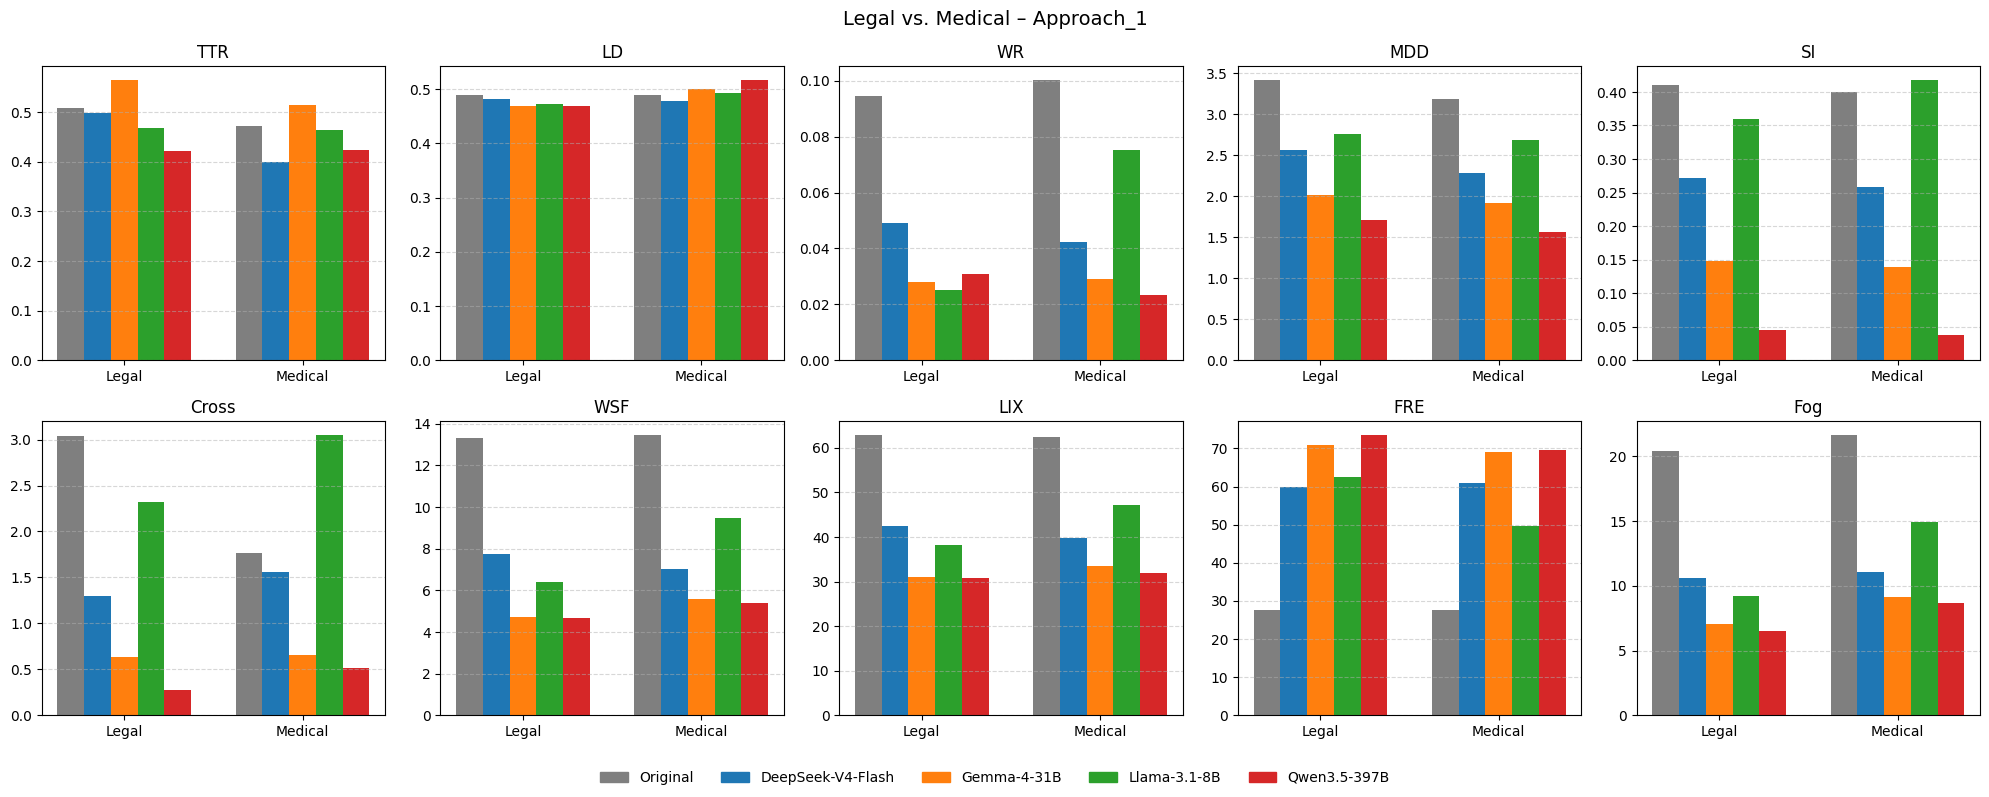

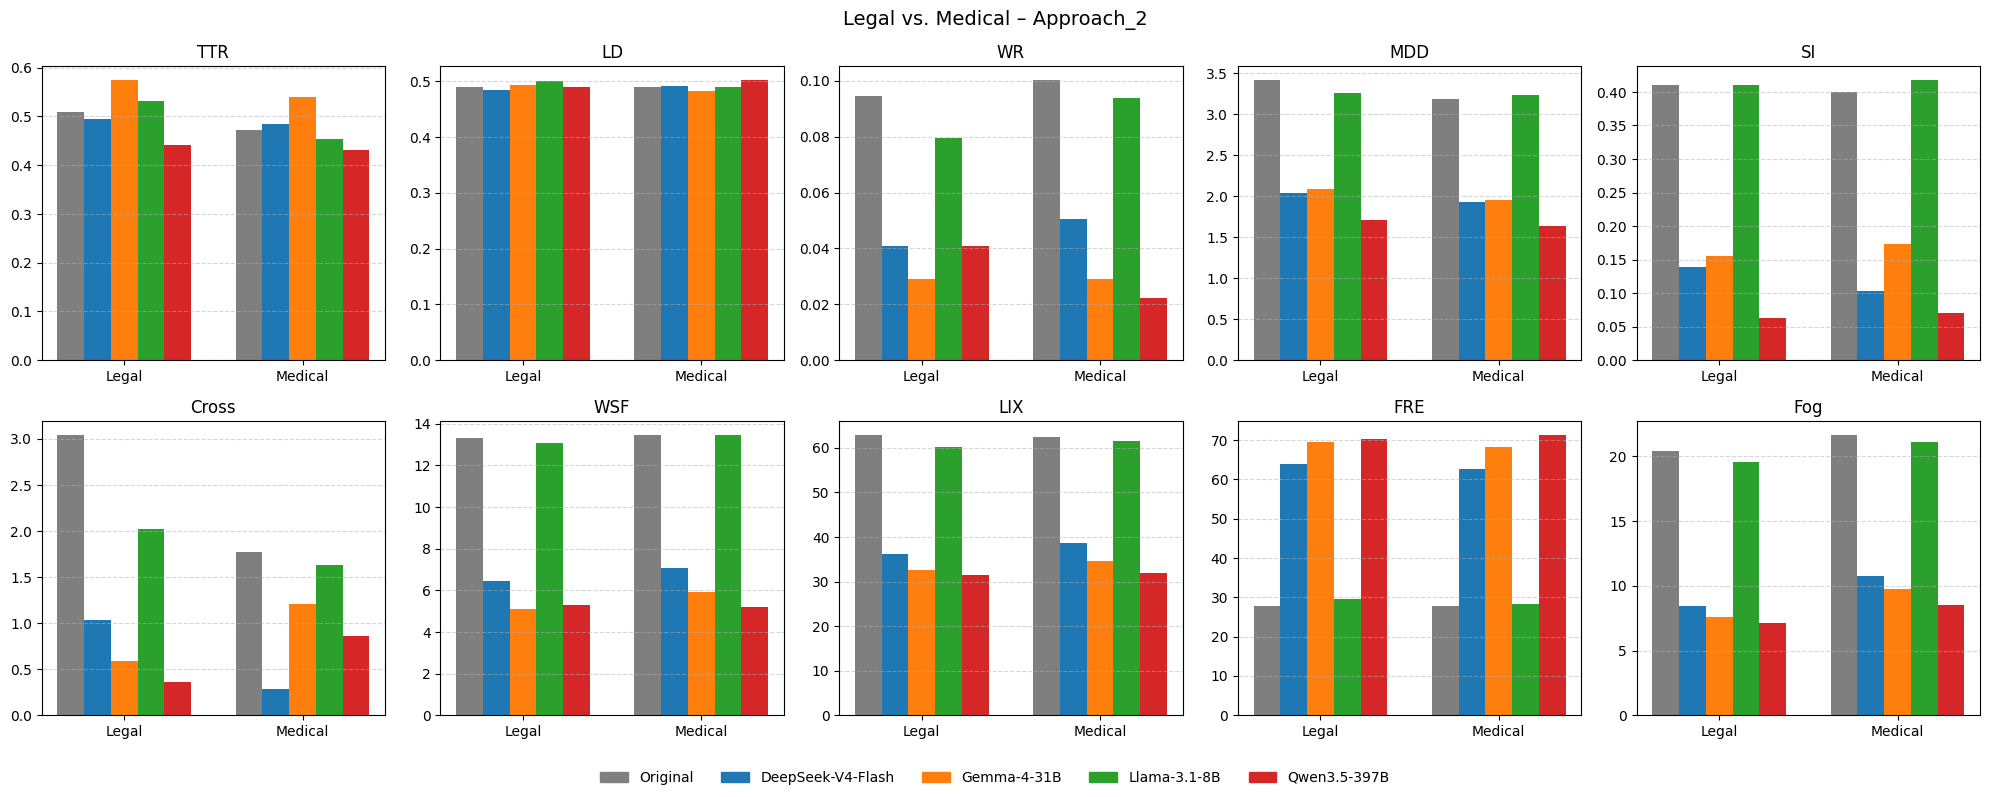

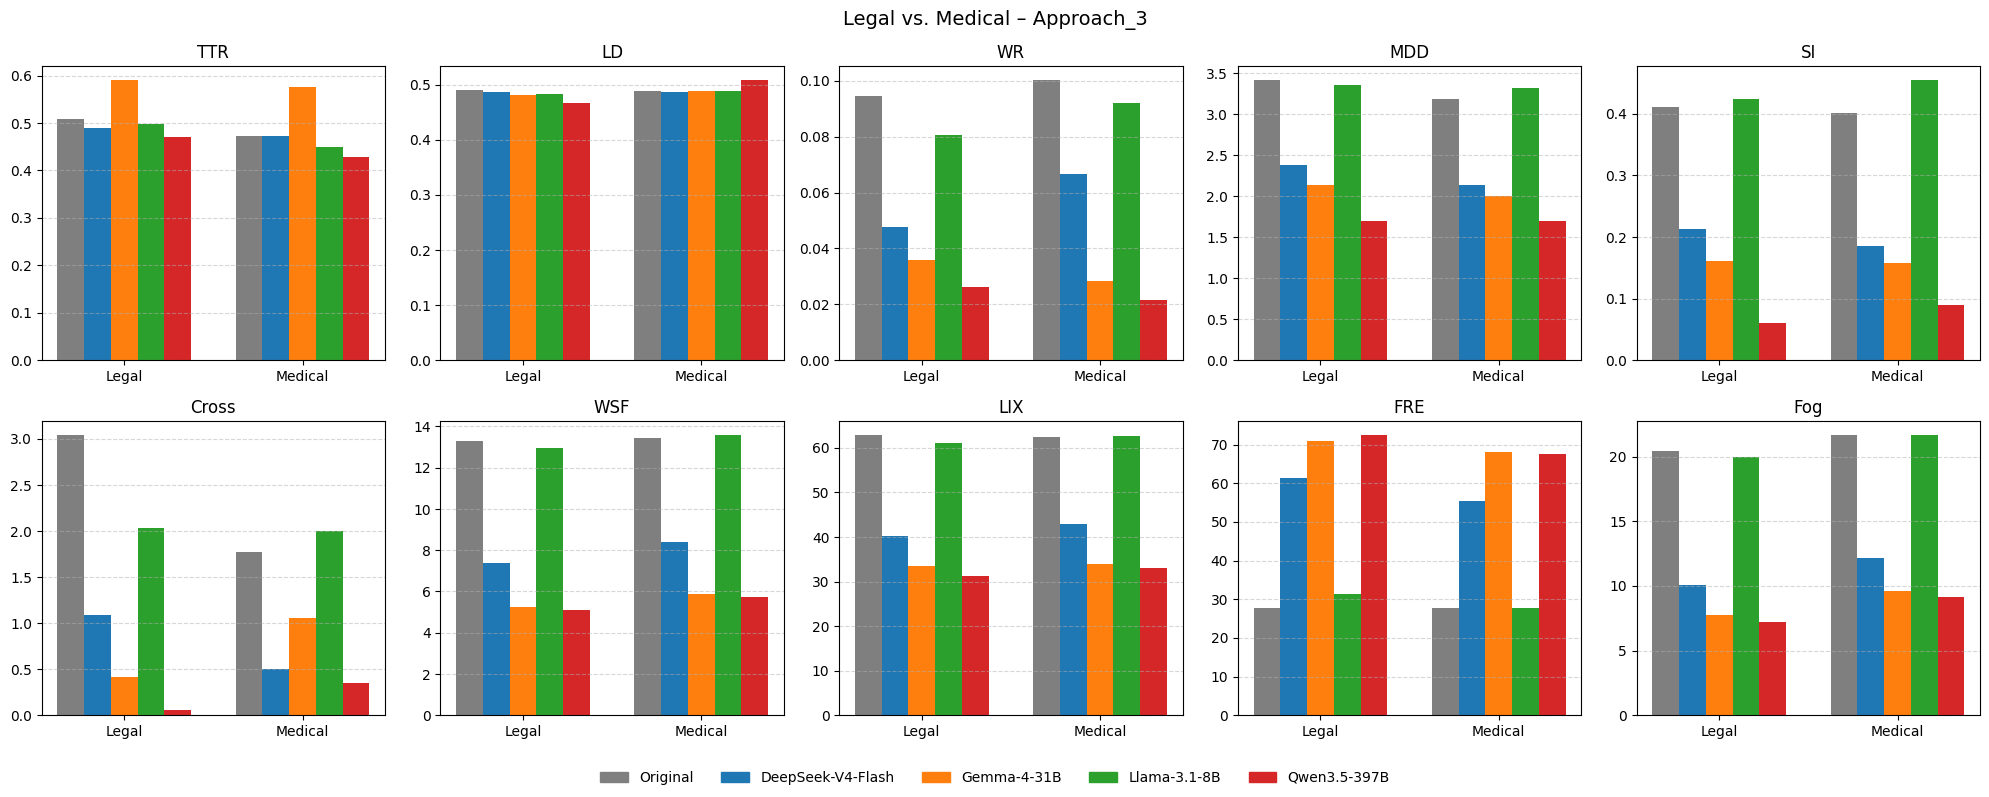

In [6]:
def plot_domain_grid(version):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()
    labels = ["Original"] + list(MODELS)
    width = 0.15

    for ax, metric in zip(axes, METRICS):
        for d_i, domain in enumerate(["Legal", "Medical"]):
            # Original = official German source text (same for all models)
            original = scores["Qwen3.5-397B"].loc[scores["Qwen3.5-397B"]["Domain"] == domain, f"{metric}_Original"].mean()
            means = [original] + [df.loc[df["Domain"] == domain, f"{metric}_{version}"].mean() for df in scores.values()]
            for i, (label, h) in enumerate(zip(labels, means)):
                ax.bar(d_i + (i - 2) * width, h, width, color=MODEL_COLORS[label])
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Legal", "Medical"])
        ax.set_title(metric)
        ax.grid(axis="y", linestyle="--", alpha=0.5)

    handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[l]) for l in labels]
    fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False)
    fig.suptitle(f"Legal vs. Medical – {version}", fontsize=14)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.savefig(os.path.join(RESULTS_DIR, f"Legal_vs_Medical_{version}.png"), dpi=150)
    plt.show()


for version in APPROACHES:
    plot_domain_grid(version)

## Findings

* After Holm correction, almost no metric differs between legal and medical outputs. With only 5 vs. 5 texts the tests have very little power.
  * **Llama-3.1-8B, Approach_1:** WR and Fog are lower for legal texts.
  * **Qwen3.5-397B, Approach_1:** LD is lower for legal texts. This matches the paper, where LD was the only robust domain difference.
* The **Original** (official German source texts) shows no significant domain difference either. Legal sources have more dependency crossings, but this is not significant after Holm correction (d = 1.74, p_adj = 0.34).
* The effect sizes (table above) point in the same direction across models, even where the result is not significant:
  * legal outputs have a **lower Fog index** (d ≈ −0.8 to −1.6)
  * legal outputs have a **higher TTR** (d ≈ +0.4 to +0.8)
* **Conclusion:** in this dataset the text type has only a small effect on output complexity. Clear statements would need more texts per domain.
